# Advanced structure visualization

See the [Gallery](gallery.qmd) for publication-ready Plotly and Three.js scenes (framework, pockets, windows, pore graphs, percolation).

Mofography ships two 3D backends:

| Backend | Best for |
|---|---|
| **Plotly** (`mgr.plot_*` traces, `go.Figure`) | Static PNG export, notebooks, publication figures, compositing with Plotly layouts |
| **Three.js** (`Figure3js`, `plot_*_3js`, `show_mof_threejs`) | Smooth interactive viewing, large scenes, background gradients, exploded views, standalone HTML |

This notebook keeps the original Plotly customization examples (meshes, aromatic rings, fake adsorbates) and adds a minimal Three.js section. For full Three.js coverage see [Three.js plotting](threejs_plotting.qmd).


## Tips

- API docs: `help(mgr.function_name)` or `mgr.function_name?` in a notebook.
- Framework traces are 3D meshes (spheres, cylinders). Lower `theta_resolution` / `phi_resolution` for quick views; raise them for publication figures.
- Docs site builds use `renderer='png'` so pages stay lightweight. Use the collapsed **Interactive version** callouts for rotatable Plotly or saved HTML.


## Imports


In [1]:
import os
import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
from ase.io import read
import mofography as mgr
from mofography import Figure3js

path_to_cif = os.path.join("..", "examples", "TestCIFs", "P1-IRMOF-1.cif")
pio.renderers.default = "png"


## Load IRMOF-1

Any ASE-readable format works. Covalent bonds are required for bond meshes and aromatic highlights (`update_with_covalent_bonds`).


In [2]:
filename = os.path.abspath(path_to_cif)
mat_atoms = read(filename)
mat_updated = mgr.update_with_covalent_bonds(mat_atoms)
print(mat_updated.get_chemical_formula(), len(mat_updated), "atoms")


/Users/arungopalan/miniforge3/envs/mgr_env/lib/python3.13/site-packages/ase/io/cif.py:411: UserWarning: crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!
  warnings.warn(


C240H96O104Zn32 472 atoms


## Plotly: framework and unit cell

`plot_framework_as_mesh` returns trace(s); combine them with `plot_cell` on a `go.Figure`. Connection plots use `plot_connections_as_it_is` (see below).


[TIMING batched_mesh_for_atoms] 472 atoms, 1024 bonds | spheres: 0.00s, cylinders: 0.00s, concat: 0.00s | total faces: 212480


/Users/arungopalan/repos/mofography/mofography/visualize.py:2531: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  vertices_per_sphere = int(len(vertexcolors[vertexcolors!=bond_rgba_string])/ase_atoms.get_number_of_atoms())
/Users/arungopalan/repos/mofography/mofography/visualize.py:2532: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  vertex_atom_ids = np.repeat(np.arange(ase_atoms.get_number_of_atoms()), vertices_per_sphere)


No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]


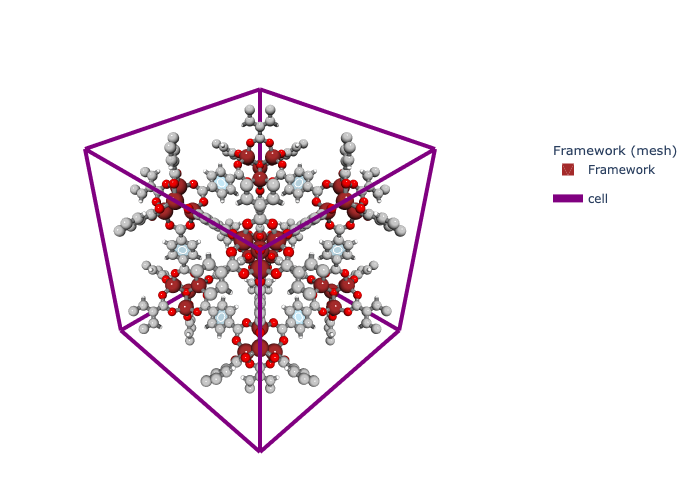

In [3]:
go.Figure(
    [*mgr.plot_framework_as_mesh(mat_updated, stylize=True), mgr.plot_cell(mat_updated)],
    layout=mgr.white_layout,
).show()


::: {.callout-note collapse="true" title="Interactive version"}
```python
fig = go.Figure(
    [*mgr.plot_framework_as_mesh(mat_updated, stylize=True), mgr.plot_cell(mat_updated)],
    layout=mgr.white_layout,
)
fig.show(renderer="notebook_connected")
```
:::


## Plotly: pore-graph connections

Run segmentation once, then overlay windows as edges with `plot_connections_as_it_is`.


[RAYON] current_num_threads = 14
[RAYON] current_num_threads = 14
/Users/arungopalan/repos/mofography/mofography/helper.py:623: RuntimeWarning: overflow encountered in scalar subtract
  pos_minus[dim] = max(pos_minus[dim] - 1, 0)


[pocket_maxima_check] Region 1: pocket_radius from maxima_info (5.493 Å) underestimates true region max (5.846 Å) by 0.353 Å; this suggests a missing or under-detected maximum.


[pocket_maxima_check] Region 3: pocket_radius from maxima_info (5.493 Å) underestimates true region max (5.846 Å) by 0.353 Å; this suggests a missing or under-detected maximum.


[pocket_maxima_check] Region 4: pocket_radius from maxima_info (5.284 Å) underestimates true region max (5.629 Å) by 0.345 Å; this suggests a missing or under-detected maximum.


[pocket_maxima_check] Region 5: pocket_radius from maxima_info (5.493 Å) underestimates true region max (5.846 Å) by 0.353 Å; this suggests a missing or under-detected maximum.


[pocket_maxima_check] Region 9: pocket_radius from maxima_info (5.493 Å) underestimates true region max (5.846 Å) by 0.353 Å; this suggests a missing or under-detected maximum.


... (6 outputs left out)

[pocket_maxima_check] Region 17: pocket_radius from maxima_info (5.493 Å) underestimates true region max (5.846 Å) by 0.353 Å; this suggests a missing or under-detected maximum.


[pocket_maxima_check] Region 18: pocket_radius from maxima_info (5.493 Å) underestimates true region max (5.846 Å) by 0.353 Å; this suggests a missing or under-detected maximum.


[TIMING batched_mesh_for_atoms] 472 atoms, 1024 bonds | spheres: 0.00s, cylinders: 0.00s, concat: 0.00s | total faces: 212480


/Users/arungopalan/repos/mofography/mofography/visualize.py:2531: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  vertices_per_sphere = int(len(vertexcolors[vertexcolors!=bond_rgba_string])/ase_atoms.get_number_of_atoms())
/Users/arungopalan/repos/mofography/mofography/visualize.py:2532: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  vertex_atom_ids = np.repeat(np.arange(ase_atoms.get_number_of_atoms()), vertices_per_sphere)


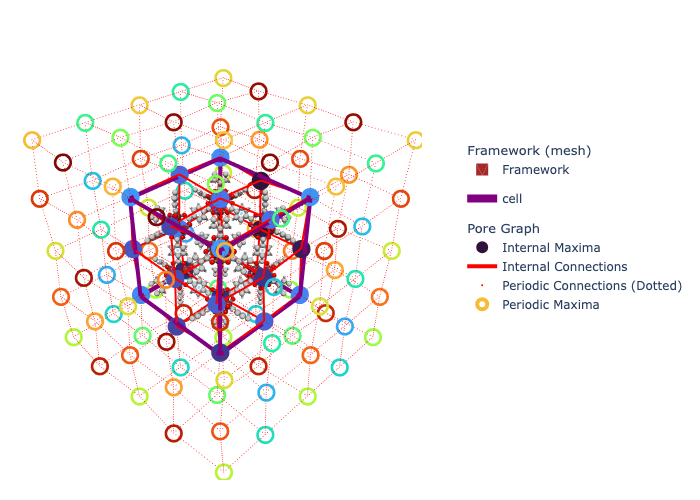

In [4]:
spacing = 0.5
dgrid = mgr.dgrid_from_atoms_rust(mat_updated, spacing=spacing).astype(np.float32)
seg = mgr.do_periodic_segmentation_rust(
    dgrid,
    mat_updated,
    spacing=spacing,
    mask_thickness=0.05,
    h=0.2,
    min_distance=1.5,
    threshold_abs=1.5,
    compute_connections=True,
    return_dgrid=True,
    disable_tqdm=True,
)
conn_traces = mgr.plot_connections_as_it_is(
    seg["connections"],
    seg["all_maxima"],
    seg["regions"].shape,
    mat_updated,
)
go.Figure(
    [*mgr.plot_framework_as_mesh(mat_updated, stylize=True), mgr.plot_cell(mat_updated), *conn_traces],
    layout=mgr.white_layout,
).show()


## Three.js: framework and save HTML

Chain `plot_*_3js` on `Figure3js`. The docs build does not embed heavy iframes; we only write a standalone file (open it locally or host it yourself).

Depth: [Three.js plotting](threejs_plotting.qmd). One-liner export: `fig.save_html("scene.html")`.


In [5]:
fig3 = (
    Figure3js(layout="white")
    .plot_framework_as_mesh_3js(mat_updated)
    .plot_cell_3js(mat_updated, color="orange")
    .plot_connections_as_it_is_3js(
        seg["connections"],
        seg["all_maxima"],
        seg["regions"].shape,
        mat_updated,
    )
)
html_path = os.path.abspath("_framework_viz_threejs_demo.html")
fig3.save_html(html_path)
print(f"Wrote interactive scene to {html_path}")


Wrote interactive scene to /Users/arungopalan/repos/mofography/docs/_framework_viz_threejs_demo.html


::: {.callout-note collapse="true" title="Interactive version"}
```python
fig3 = (
    Figure3js(layout="white")
    .plot_framework_as_mesh_3js(mat_updated)
    .plot_cell_3js(mat_updated, color="orange")
)
fig3.show(height=600)
fig3.save_html("irmof1_framework.html")
```
:::


## Plotly: customize atoms and bonds

Build sphere and cylinder meshes separately, then style with `plot_mesh`.


In [6]:
spheres = mgr.spheres_for_atoms(mat_updated, theta_resolution=30, phi_resolution=30)
cylinders = mgr.cylinders_for_bonds(
    mat_updated.info["covalent_bonds"], mat_updated, radius=0.15
)


## Plotly: aromatic rings and partial framework


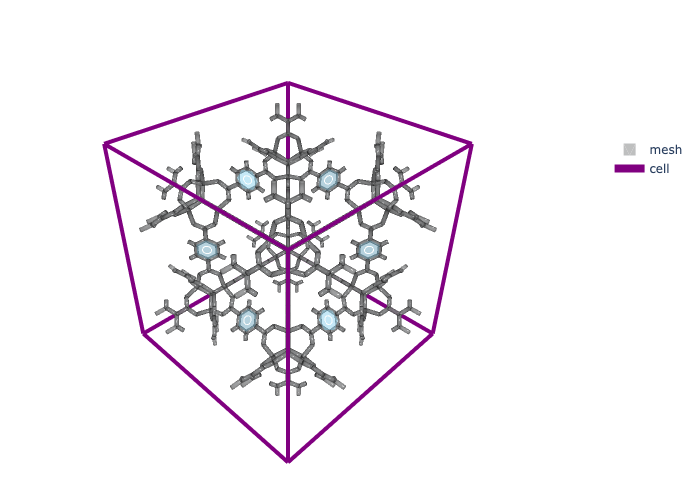

In [7]:
go.Figure(
    [
        mgr.plot_mesh(cylinders, stylize=True, opacity=0.5),
        *mgr.plot_aromatic_rings(mat_updated),
        mgr.plot_cell(mat_updated),
    ],
    layout=mgr.white_layout,
).show()


::: {.callout-note collapse="true" title="Interactive version"}
```python
fig = go.Figure(
    [
        mgr.plot_mesh(cylinders, stylize=True, opacity=0.5),
        *mgr.plot_aromatic_rings(mat_updated),
        mgr.plot_cell(mat_updated),
    ],
    layout=mgr.white_layout,
)
fig.show(renderer="notebook_connected")
```
:::


## Plotly: fake adsorbates (random spheres in the cell)


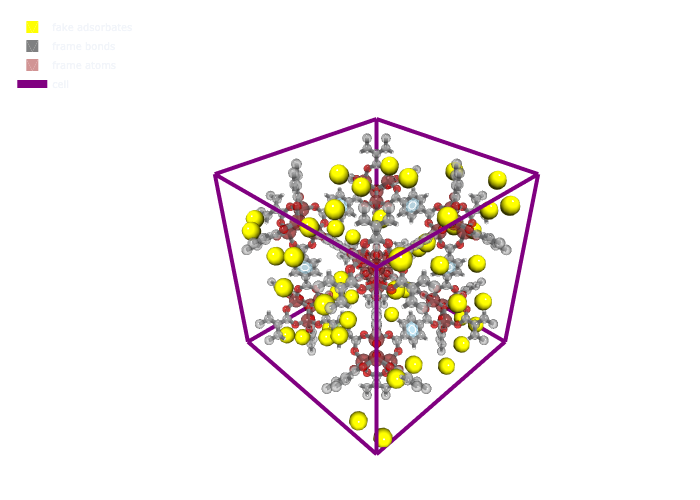

In [8]:
nadsorbates = 50
random_positions = np.random.default_rng(0).random((nadsorbates, 3))
from ase.geometry import complete_cell
from ase import Atoms
from ase.data import covalent_radii

cell_matrix = complete_cell(mat_updated.get_cell())
random_positions = np.dot(cell_matrix, random_positions.T).T
fake_atoms = Atoms(
    positions=random_positions,
    cell=mat_updated.get_cell(),
    symbols=["C"] * nadsorbates,
    pbc=True,
)
scale = 1.5
radii = covalent_radii[fake_atoms.get_atomic_numbers()]
spheres_1 = mgr.spheres_for_atoms(fake_atoms, scale=scale, radii=radii)

go.Figure(
    [
        mgr.plot_mesh(spheres_1, opacity=1, stylize=True, color="yellow", name="fake adsorbates"),
        mgr.plot_mesh(cylinders, stylize=False, opacity=1, name="frame bonds"),
        mgr.plot_mesh(spheres, opacity=0.5, stylize=True, name="frame atoms"),
        *mgr.plot_aromatic_rings(mat_updated),
        mgr.plot_cell(mat_updated),
    ],
    layout=mgr.epic_layout,
).show()


::: {.callout-note collapse="true" title="Interactive version"}
```python
fig = go.Figure(
    [
        mgr.plot_mesh(spheres_1, opacity=1, stylize=True, color="yellow", name="fake adsorbates"),
        mgr.plot_mesh(cylinders, stylize=False, opacity=1, name="frame bonds"),
        mgr.plot_mesh(spheres, opacity=0.5, stylize=True, name="frame atoms"),
        *mgr.plot_aromatic_rings(mat_updated),
        mgr.plot_cell(mat_updated),
    ],
    layout=mgr.epic_layout,
)
fig.show(renderer="notebook_connected")
```
:::


## Where to go next

- [Gallery](gallery.qmd) — curated Plotly and Three.js scenes
- [Three.js plotting](threejs_plotting.qmd) — pockets, surfaces, percolation, pore graphs
- [Basic structure visualization](quick_structure_visualization.ipynb) — first Plotly views
- [Quick start](quick_start.qmd) — `show_mof_plotly` / `show_mof_threejs` on a full segmentation
